In [1]:
import sys
import pandas as pd

print("Python executable:", sys.executable)
print("Python version:", sys.version)
print("Pandas version:", pd.__version__)

Python executable: d:\DAC\CHURN_PREDICTION\.venv\Scripts\python.exe
Python version: 3.14.7 (tags/v3.14.7:823f032, Aug  5 2026, 10:51:32) [MSC v.1944 64 bit (AMD64)]
Pandas version: 3.1.1


# Churn Prediction – Exploratory Data Analysis

## 1. Project Overview

This notebook explores merchant-level financial GMV, and Search Traffic features to understand patterns associated with next-month churn.

**Dataset:** `data/processed/training_set.csv`

**Observation grain:** One merchant × one monthly snapshot.

**Target:** `churn_next_30d`

**Data split:**
- Train: June–July 2026
- Test: August 2026

## 2. EDA Objectives

1. Analyze churn by merchant tenure and MRR.
2. Investigate churn differences by GMV and Search data availability.
3. Compare GMV and Search activity between churned and non-churned merchants.
4. Identify skewed features and potential outliers.
5. Investigate the relationship between missing values and churn.
6. Assess churn stability between June and July 2026.

## A. Data Preparation

In [2]:
# 1. Import libraries
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 2. Set project path
PROJECT_ROOT = (
    Path.cwd().parent
    if Path.cwd().name == "notebooks"
    else Path.cwd()
)
DATA_PATH = PROJECT_ROOT / "data" / "processed" / "training_set.csv"

# 3. Load dataset
df = pd.read_csv(DATA_PATH)

# 4. Convert snapshot_month to datetime
df["snapshot_month"] = pd.to_datetime(df["snapshot_month"])

# 5. Basic information
print("Project root:", PROJECT_ROOT)
print("Dataset path:", DATA_PATH)
print("Python executable:", sys.executable)
print("Dataset shape:", df.shape)
print("\nSnapshot months:")
print(df["snapshot_month"].value_counts().sort_index())
print("\nData split:")
print(df["split"].value_counts())
print("\nTarget distribution:")
print(df["churn_next_30d"].value_counts())

Matplotlib is building the font cache; this may take a moment.


Project root: d:\DAC\CHURN_PREDICTION
Dataset path: d:\DAC\CHURN_PREDICTION\data\processed\training_set.csv
Python executable: d:\DAC\CHURN_PREDICTION\.venv\Scripts\python.exe
Dataset shape: (25556, 46)

Snapshot months:
snapshot_month
2026-06-01    8669
2026-07-01    8512
2026-08-01    8375
Name: count, dtype: int64

Data split:
split
train    17181
test      8375
Name: count, dtype: int64

Target distribution:
churn_next_30d
0    24889
1      667
Name: count, dtype: int64


## B. EDA

### 1. Churn by Merchant Tenure and MRR (dataset)

In [3]:
# Create a working copy for EDA
eda_df = df.copy()

# 1. Group merchants by tenure
tenure_bins = [-np.inf, 3, 6, 12, 24, 36, np.inf]
tenure_labels = [
    "0-3 months",
    "4-6 months",
    "7-12 months",
    "13-24 months",
    "25-36 months",
    "Over 36 months"
]
eda_df["tenure_group"] = pd.cut(
    eda_df["tenure_months"],
    bins=tenure_bins,
    labels=tenure_labels
)

# 2. Group merchants by EOM MRR quartiles
eda_df["mrr_group"] = pd.qcut(
    eda_df["eom_mrr"],
    q=4,
    duplicates="drop"
)

# 3. Calculate churn statistics
def calculate_churn_rate(data, group_column):
    result = (
        data.groupby(group_column, observed=True)
        .agg(
            merchant_months=("churn_next_30d", "size"),
            churn_count=("churn_next_30d", "sum"),
            churn_rate=("churn_next_30d", "mean")
        )
        .reset_index()
    )

    result["churn_rate_pct"] = result["churn_rate"] * 100

    return result.drop(columns="churn_rate")

# 4. Churn by tenure
tenure_churn = calculate_churn_rate(
    eda_df, "tenure_group"
)
print("CHURN RATE BY TENURE")
display(tenure_churn)

# 5. Churn by MRR
mrr_churn = calculate_churn_rate(
    eda_df, "mrr_group"
)
print("\nCHURN RATE BY MRR")
display(mrr_churn)

CHURN RATE BY TENURE


,tenure_group,merchant_months,churn_count,churn_rate_pct
0,0-3 months,892,82,9.192825
1,4-6 months,520,24,4.615385
2,7-12 months,1078,39,3.617811
3,13-24 months,1847,53,2.869518
4,25-36 months,3052,77,2.522936
5,Over 36 months,18167,392,2.157759



CHURN RATE BY MRR


,mrr_group,merchant_months,churn_count,churn_rate_pct
0,"(0.099, 19.0]",8681,178,2.050455
1,"(19.0, 29.0]",5158,181,3.509112
2,"(29.0, 79.0]",5836,141,2.416038
3,"(79.0, 5500.0]",5881,167,2.839653


### Churn by Merchant Tenure and MRR (training set)

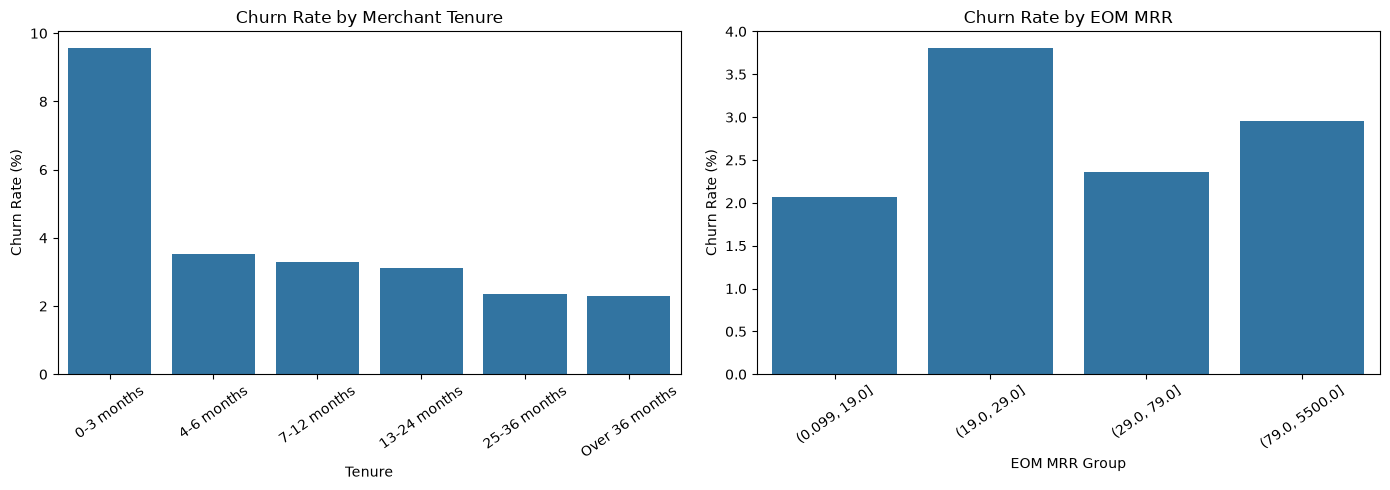

,tenure_group,merchant_months,churn_count,churn_rate_pct
0,0-3 months,616,59,9.577922
1,4-6 months,339,12,3.539823
2,7-12 months,730,24,3.287671
3,13-24 months,1250,39,3.120000
4,25-36 months,2079,49,2.356902
5,Over 36 months,12167,279,2.293088


,mrr_group,merchant_months,churn_count,churn_rate_pct
0,"(0.099, 19.0]",5847,121,2.069437
1,"(19.0, 29.0]",3464,132,3.810624
2,"(29.0, 79.0]",3945,93,2.357414
3,"(79.0, 5500.0]",3925,116,2.955414


In [4]:
# Use training data only for EDA and feature decisions
train_eda = df[df["split"] == "train"].copy()

# Create tenure groups
tenure_bins = [-np.inf, 3, 6, 12, 24, 36, np.inf]
tenure_labels = [
    "0-3 months", "4-6 months", "7-12 months",
    "13-24 months", "25-36 months", "Over 36 months"
]

train_eda["tenure_group"] = pd.cut(
    train_eda["tenure_months"],
    bins=tenure_bins,
    labels=tenure_labels
)

# Create MRR quartile groups based on training data
train_eda["mrr_group"] = pd.qcut(
    train_eda["eom_mrr"],
    q=4,
    duplicates="drop"
)

# Calculate churn statistics
tenure_churn_train = calculate_churn_rate(
    train_eda, "tenure_group"
)

mrr_churn_train = calculate_churn_rate(
    train_eda, "mrr_group"
)

# Plot churn by tenure
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(
    data=tenure_churn_train,
    x="tenure_group",
    y="churn_rate_pct",
    ax=axes[0]
)
axes[0].set_title("Churn Rate by Merchant Tenure")
axes[0].set_xlabel("Tenure")
axes[0].set_ylabel("Churn Rate (%)")
axes[0].tick_params(axis="x", rotation=35)

# Plot churn by MRR
sns.barplot(
    data=mrr_churn_train,
    x="mrr_group",
    y="churn_rate_pct",
    ax=axes[1]
)
axes[1].set_title("Churn Rate by EOM MRR")
axes[1].set_xlabel("EOM MRR Group")
axes[1].set_ylabel("Churn Rate (%)")
axes[1].tick_params(axis="x", rotation=35)

plt.tight_layout()
plt.show()

display(tenure_churn_train)
display(mrr_churn_train)

**Key findings:**

- Churn risk is highest among merchants with 0–3 months of tenure (9.58%), approximately 4.18 times the rate of merchants with over 36 months of tenure (2.29%).
- Churn rates generally decrease as merchant tenure increases, suggesting that early-stage merchants are more vulnerable to churn.
- The relationship between MRR and churn is non-linear. Merchants with monthly MRR between 19 and 29 have the highest churn rate (3.81%).
- Tenure and MRR should both be retained as candidate predictors for further modeling.

### 2. Churn by GMV and Search Data Availability

CHURN BY GMV DATA AVAILABILITY


,availability,merchant_months,churn_count,churn_rate_pct
0,No data,2353,111,4.717382
1,Has data,14828,351,2.367143


CHURN BY SEARCH DATA AVAILABILITY


,availability,merchant_months,churn_count,churn_rate_pct
0,No data,4481,186,4.150859
1,Has data,12700,276,2.173228


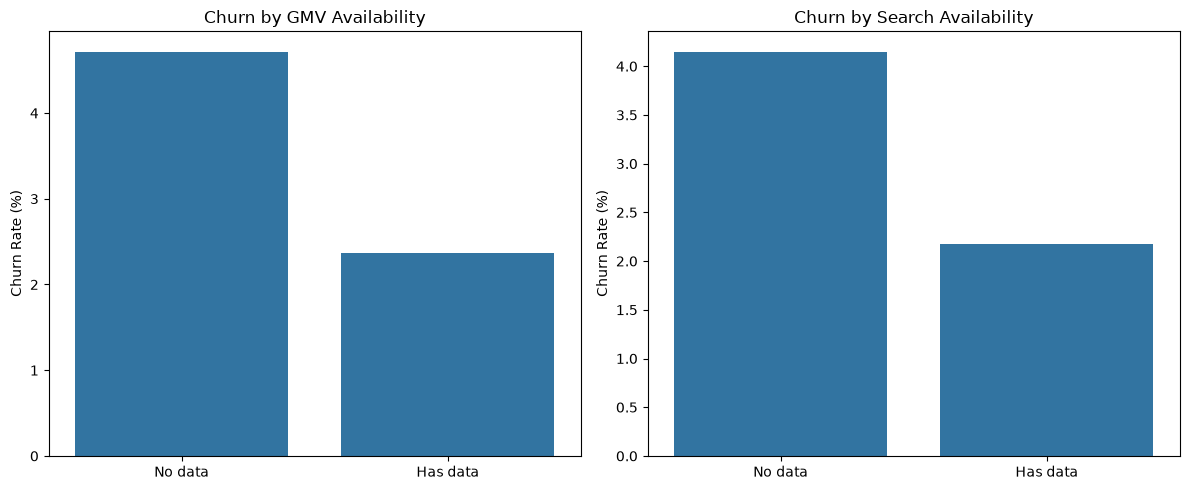

In [5]:
# Calculate churn rate by data availability
def availability_churn(data, feature):
    result = (
        data.groupby(feature, observed=True)
        .agg(
            merchant_months=("churn_next_30d", "size"),
            churn_count=("churn_next_30d", "sum"),
            churn_rate=("churn_next_30d", "mean")
        )
        .reset_index()
    )

    result["availability"] = result[feature].map({
        0: "No data",
        1: "Has data"
    })

    result["churn_rate_pct"] = result["churn_rate"] * 100

    return result[
        ["availability", "merchant_months",
         "churn_count", "churn_rate_pct"]
    ]


# GMV availability
gmv_availability = availability_churn(
    train_eda, "has_gmv_data"
)

# Search availability
search_availability = availability_churn(
    train_eda, "has_search_data"
)

print("CHURN BY GMV DATA AVAILABILITY")
display(gmv_availability)

print("CHURN BY SEARCH DATA AVAILABILITY")
display(search_availability)


# Visualize results
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.barplot(
    data=gmv_availability,
    x="availability",
    y="churn_rate_pct",
    ax=axes[0]
)
axes[0].set_title("Churn by GMV Availability")
axes[0].set_xlabel("")
axes[0].set_ylabel("Churn Rate (%)")

sns.barplot(
    data=search_availability,
    x="availability",
    y="churn_rate_pct",
    ax=axes[1]
)
axes[1].set_title("Churn by Search Availability")
axes[1].set_xlabel("")
axes[1].set_ylabel("Churn Rate (%)")

plt.tight_layout()
plt.show()

**Key findings:**

- Merchants without GMV records have a churn rate of 4.72%, approximately 1.99 times that of merchants with GMV data (2.37%).
- Merchants without Search Traffic records also show a higher churn rate (4.15%) than merchants with available data (2.17%).
- Data availability indicators may provide predictive information and should be retained as candidate features.

### 3. Business Activity Patterns Before Churn

In [7]:
# Select key activity features
key_features = [
    "gmv_growth_30d",
    "gmv_growth_60d",
    "searches_30d",
    "searches_60d",
    "orders_30d",
    "orders_60d",
    "searches_growth_30d",
    "searches_growth_60d",
    "orders_growth_30d",
    "orders_growth_60d"
]

# Compare median values by churn status
activity_median = (
    train_eda
    .groupby("churn_next_30d")[key_features]
    .median()
    .T
    .rename(columns={
        0: "Non-churn",
        1: "Churn"
    })
)

# Add the number of available observations
activity_count = (
    train_eda
    .groupby("churn_next_30d")[key_features]
    .count()
    .T
    .rename(columns={
        0: "Non-churn count",
        1: "Churn count"
    })
)

activity_summary = activity_count.join(activity_median)

display(activity_summary.round(3))

churn_next_30d,Non-churn count,Churn count,Non-churn,Churn
gmv_growth_30d,13935,331,-0.027,-0.158
gmv_growth_60d,13535,324,-0.006,-0.067
searches_30d,12424,276,1854.500,677.500
searches_60d,12118,251,4045.500,2436.000
orders_30d,12424,276,2.000,0.000
orders_60d,12118,251,4.000,2.000
searches_growth_30d,12118,251,0.017,-0.111
searches_growth_60d,11761,228,-0.029,-0.186
orders_growth_30d,7138,137,-0.049,-0.333
orders_growth_60d,7713,147,-0.090,-0.298


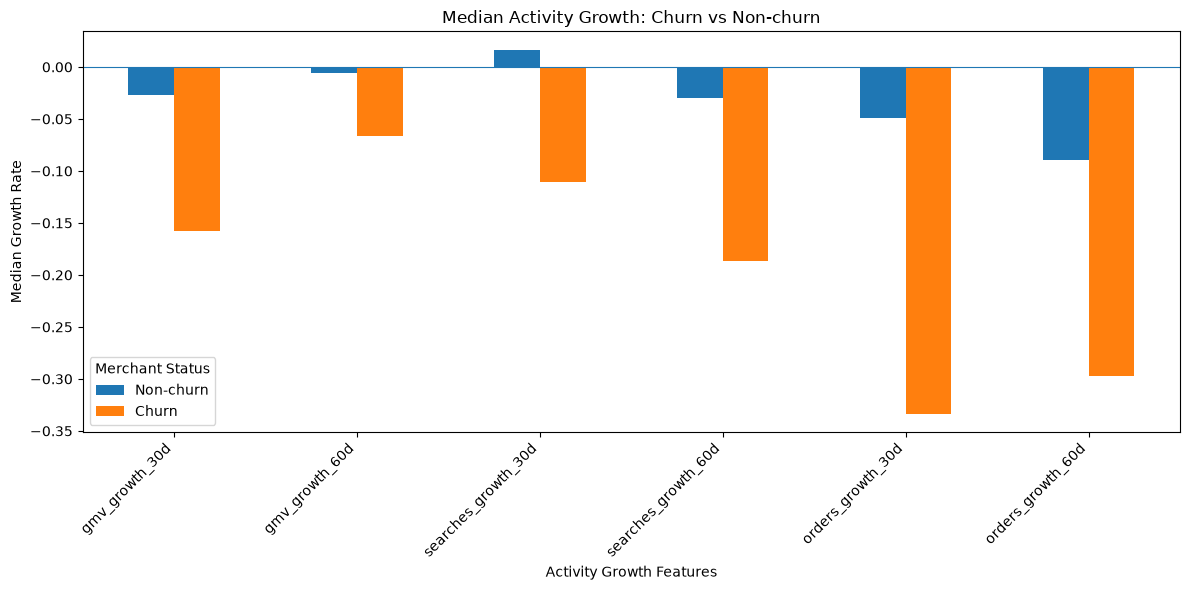

In [8]:
growth_features = [
    "gmv_growth_30d",
    "gmv_growth_60d",
    "searches_growth_30d",
    "searches_growth_60d",
    "orders_growth_30d",
    "orders_growth_60d"
]

growth_median = (
    train_eda
    .groupby("churn_next_30d")[growth_features]
    .median()
    .T
    .rename(columns={
        0: "Non-churn",
        1: "Churn"
    })
)

growth_median.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Median Activity Growth: Churn vs Non-churn")
plt.xlabel("Activity Growth Features")
plt.ylabel("Median Growth Rate")
plt.xticks(rotation=45, ha="right")
plt.axhline(0, linewidth=0.8)
plt.legend(title="Merchant Status")
plt.tight_layout()
plt.show()

**Key findings:**

- Merchants who churn in the following month generally show weaker business activity than non-churned merchants.
- The median GMV growth rate over 30 days is -15.8% for churned merchants, compared with -2.7% for non-churned merchants.
- Churned merchants also show lower Search Traffic volume and more negative Search growth rates.
- Order activity provides another potential churn signal. The median order count over 30 days is zero among churned merchants, compared with two among non-churned merchants.
- These patterns suggest that declining GMV, Search Traffic, and order activity may be useful predictive signals.

### 4. Highly skewed features

In [10]:
# Exclude binary flags from skewness analysis
binary_features = [
    "has_search_data",
    "has_gmv_data",
    "multi_currency_flag"
]

continuous_features = [
    col for col in numeric_features
    if col not in binary_features
]

# Calculate distribution statistics
skewness_summary = pd.DataFrame({
    "non_null_count": train_eda[continuous_features].count(),
    "skewness": train_eda[continuous_features].skew(),
    "min": train_eda[continuous_features].min(),
    "median": train_eda[continuous_features].median(),
    "max": train_eda[continuous_features].max()
})

# Classify skewness
def classify_skewness(value):
    if abs(value) < 0.5:
        return "Approximately symmetric"
    elif abs(value) < 1:
        return "Moderately skewed"
    else:
        return "Highly skewed"

skewness_summary["skewness_level"] = (
    skewness_summary["skewness"]
    .apply(classify_skewness)
)

# Sort by absolute skewness
skewness_summary["abs_skewness"] = (
    skewness_summary["skewness"].abs()
)

skewness_summary = skewness_summary.sort_values(
    "abs_skewness",
    ascending=False
)

display(skewness_summary.round(3))

,non_null_count,skewness,min,median,max,skewness_level,abs_skewness
gmv_growth_60d,13859,107.158,-1.000,-0.007,1.108065e+04,Highly skewed,107.158
searches_growth_30d,12369,103.560,-1.000,0.015,3.611550e+04,Highly skewed,103.560
gmv_growth_30d,14266,95.724,-1.000,-0.030,4.469025e+04,Highly skewed,95.724
searches_growth_60d,11989,81.742,-1.000,-0.032,9.274000e+03,Highly skewed,81.742
search_to_product_click_rate_60d,12369,71.530,0.000,0.123,6.718900e+01,Highly skewed,71.530
search_to_product_click_rate_30d,12700,68.930,0.000,0.117,4.799000e+01,Highly skewed,68.930
orders_growth_30d,7275,67.443,-1.000,-0.054,4.535000e+02,Highly skewed,67.443
product_clicks_growth_60d,10136,60.671,-1.000,-0.043,6.759500e+03,Highly skewed,60.671
mrr_growth_rate,16953,58.617,-0.875,0.000,2.202200e+01,Highly skewed,58.617
orders_growth_60d,7860,52.288,-1.000,-0.092,9.100000e+02,Highly skewed,52.288


#### 1.2. Outliers detection

In [11]:
# Calculate percentile statistics for continuous features
percentile_summary = train_eda[continuous_features].describe(
    percentiles=[0.50, 0.75, 0.90, 0.95, 0.99]
).T

percentile_summary = percentile_summary[
    ["count", "mean", "50%", "75%", "90%", "95%", "99%", "max"]
]

# Sort by maximum-to-median ratio
percentile_summary["max_median_ratio"] = (
    percentile_summary["max"]
    / percentile_summary["50%"].replace(0, np.nan)
)

percentile_summary = percentile_summary.sort_values(
    "max_median_ratio",
    ascending=False
)

display(percentile_summary.round(3))

,count,mean,50%,75%,90%,95%,99%,max,max_median_ratio
searches_growth_30d,12369.0,5.417,0.015,0.210,0.606,1.184,6.574,3.611550e+04,2467892.500
orders_30d,12700.0,104.667,2.000,24.000,151.000,362.000,1909.020,2.828000e+04,14140.000
orders_60d,12369.0,218.049,4.000,53.000,321.200,759.600,3824.400,3.359500e+04,8398.750
add_carts_30d,12700.0,484.787,16.000,143.000,709.100,1696.300,7591.320,1.264990e+05,7906.188
add_carts_60d,12369.0,1003.788,36.000,306.000,1467.200,3425.600,16036.240,2.597320e+05,7214.778
searches_30d,12700.0,23246.731,1818.000,9255.500,34858.100,79077.050,340987.390,8.332471e+06,4583.317
product_clicks_30d,12700.0,3057.645,155.000,1129.250,4850.200,11213.000,52064.880,7.024810e+05,4532.135
searches_60d,12369.0,46542.706,4004.000,19142.000,70276.800,157958.400,666921.480,1.602954e+07,4003.381
search_clicks_30d,12700.0,1624.727,96.000,667.000,2698.100,6069.600,26674.090,3.449180e+05,3592.896
gmv_60d,14339.0,510715.764,68194.652,285922.250,952879.297,1935881.989,6476700.391,2.398350e+08,3516.918


In [12]:
growth_features = [
    "gmv_growth_30d",
    "gmv_growth_60d",
    "searches_growth_30d",
    "searches_growth_60d",
    "orders_growth_30d",
    "orders_growth_60d"
]

# Inspect the 10 largest values for each growth feature
for feature in growth_features:
    print(f"\nTop 10 extreme values: {feature}")

    display(
        train_eda[
            ["shop_key", "snapshot_month", "churn_next_30d", feature]
        ]
        .dropna()
        .nlargest(10, feature)
        .round(3)
    )


Top 10 extreme values: gmv_growth_30d


C:\Users\HP\AppData\Local\Temp\ipykernel_9040\2728681476.py:20: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  .round(3)


,shop_key,snapshot_month,churn_next_30d,gmv_growth_30d
23161,store-q3bjhy3s.myshopify.com,2026-07-01,0,44690.249
22028,store-kjvfpwod.myshopify.com,2026-07-01,0,19577.779
24528,store-oad8lalw.myshopify.com,2026-06-01,0,6871.508
22290,store-dsqazavh.myshopify.com,2026-06-01,0,2524.885
24006,store-e2i2rzch.myshopify.com,2026-06-01,0,2444.443
25135,store-0ve9aybe.myshopify.com,2026-07-01,0,2278.800
25151,store-xutmehpo.myshopify.com,2026-07-01,0,1257.176
15574,store-lavd2zj1.myshopify.com,2026-07-01,0,776.674
25433,store-jah65o1v.myshopify.com,2026-07-01,0,743.696
6163,store-m81v2q80.myshopify.com,2026-06-01,0,418.350



Top 10 extreme values: gmv_growth_60d


C:\Users\HP\AppData\Local\Temp\ipykernel_9040\2728681476.py:20: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  .round(3)


,shop_key,snapshot_month,churn_next_30d,gmv_growth_60d
3244,store-uqo3yot0.myshopify.com,2026-06-01,0,11080.654
8814,store-e2i2rzch.myshopify.com,2026-07-01,0,2466.927
7815,store-njcfp2h4.myshopify.com,2026-06-01,0,1490.837
5947,store-lfgaxm3y.myshopify.com,2026-06-01,0,709.428
15574,store-lavd2zj1.myshopify.com,2026-07-01,0,347.783
13844,store-t7dxgyga.myshopify.com,2026-07-01,0,271.826
13014,store-d78lph60.myshopify.com,2026-06-01,0,191.094
1065,store-fvs6vhp7.myshopify.com,2026-06-01,0,151.727
17497,store-sa5sw4f5.myshopify.com,2026-06-01,0,130.847
17156,store-1q5y3914.myshopify.com,2026-07-01,0,113.420


... (8 outputs left out)

,shop_key,snapshot_month,churn_next_30d,orders_growth_30d
10657,store-2lqa22es.myshopify.com,2026-07-01,0,453.500
1794,store-1q5y3914.myshopify.com,2026-06-01,0,136.500
4202,store-l8l9jh6h.myshopify.com,2026-06-01,0,85.000
13301,store-ecq1ktvs.myshopify.com,2026-07-01,0,60.000
1259,store-lzqgzga9.myshopify.com,2026-07-01,0,27.000
8246,store-zld288pm.myshopify.com,2026-07-01,0,21.000
9498,store-ay8msce2.myshopify.com,2026-07-01,0,18.000
703,store-o6jkz3b6.myshopify.com,2026-07-01,0,14.297
14331,store-9t96tsvy.myshopify.com,2026-06-01,0,14.000
283,store-c230sczl.myshopify.com,2026-06-01,0,13.000



Top 10 extreme values: orders_growth_60d


C:\Users\HP\AppData\Local\Temp\ipykernel_9040\2728681476.py:20: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  .round(3)


,shop_key,snapshot_month,churn_next_30d,orders_growth_60d
10657,store-2lqa22es.myshopify.com,2026-07-01,0,910.0
7048,store-vwvfh1t2.myshopify.com,2026-06-01,0,742.0
17156,store-1q5y3914.myshopify.com,2026-07-01,0,296.0
15910,store-l8l9jh6h.myshopify.com,2026-07-01,0,276.0
14395,store-ld9bgig3.myshopify.com,2026-06-01,0,265.0
25151,store-xutmehpo.myshopify.com,2026-07-01,0,58.0
11736,store-saeu91id.myshopify.com,2026-06-01,0,36.0
5077,store-ewj7lya5.myshopify.com,2026-06-01,0,33.0
7677,store-75jqacci.myshopify.com,2026-07-01,0,28.5
1259,store-lzqgzga9.myshopify.com,2026-07-01,0,28.0


In [13]:
# Analyze extreme growth values
growth_extreme_summary = []

for feature in growth_features:
    p99 = train_eda[feature].quantile(0.99)

    extreme_data = train_eda[
        train_eda[feature] > p99
    ]

    growth_extreme_summary.append({
        "feature": feature,
        "p99_threshold": p99,
        "extreme_count": len(extreme_data),
        "extreme_pct": len(extreme_data) / train_eda[feature].notna().sum() * 100,
        "non_churn_count": (extreme_data["churn_next_30d"] == 0).sum(),
        "churn_count": (extreme_data["churn_next_30d"] == 1).sum()
    })

growth_extreme_summary = pd.DataFrame(growth_extreme_summary)

display(growth_extreme_summary.round(3))

,feature,p99_threshold,extreme_count,extreme_pct,non_churn_count,churn_count
0,gmv_growth_30d,8.311,143,1.002,141,2
1,gmv_growth_60d,4.358,139,1.003,136,3
2,searches_growth_30d,6.574,124,1.003,121,3
3,searches_growth_60d,4.427,120,1.001,119,1
4,orders_growth_30d,5.000,71,0.976,71,0
5,orders_growth_60d,5.000,66,0.840,65,1


**Key findings:**

- Most numerical features exhibit right-skewed distributions, particularly GMV, MRR, Search Traffic, and order activity volumes.
- Growth features contain extreme positive values, potentially caused by very small baseline activity in the previous period.
- Approximately 1% of observations exceed the 99th percentile for each growth feature. These observations are not exclusively associated with churn.
- Log transformation is a candidate preprocessing step for non-negative volume and monetary features.
- Growth rates should not be directly log-transformed because they can contain negative values. Clipping at the 99th percentile will be evaluated as an alternative during model development.
- No observations are removed solely because of extreme values during EDA.

### 5. Impact of missing values 

In [14]:
# Identify missing values in training data
missing_summary = pd.DataFrame({
    "missing_count": train_eda.isna().sum(),
    "missing_pct": train_eda.isna().mean() * 100
})

missing_summary = (
    missing_summary[missing_summary["missing_count"] > 0]
    .sort_values("missing_pct", ascending=False)
)

display(missing_summary.round(2))

,missing_count,missing_pct
orders_growth_30d,9906,57.66
orders_growth_60d,9321,54.25
add_carts_growth_30d,7932,46.17
cart_to_order_rate_30d,7862,45.76
add_carts_growth_60d,7720,44.93
cart_to_order_rate_60d,7504,43.68
product_clicks_growth_60d,7045,41.00
search_clicks_growth_60d,7045,41.00
product_clicks_growth_30d,7029,40.91
search_clicks_growth_30d,7029,40.91


In [15]:
# Compare churn rates between missing and available observations

missing_churn_results = []

for feature in missing_summary.index:
    missing_mask = train_eda[feature].isna()

    missing_group = train_eda[missing_mask]
    available_group = train_eda[~missing_mask]

    missing_churn_results.append({
        "feature": feature,
        "missing_count": len(missing_group),
        "missing_churn_rate": missing_group["churn_next_30d"].mean() * 100,
        "available_count": len(available_group),
        "available_churn_rate": available_group["churn_next_30d"].mean() * 100,
        "rate_difference_pp": (
            missing_group["churn_next_30d"].mean()
            - available_group["churn_next_30d"].mean()
        ) * 100
    })

missing_churn_summary = pd.DataFrame(missing_churn_results)

missing_churn_summary = missing_churn_summary.sort_values(
    "rate_difference_pp",
    ascending=False
)

display(missing_churn_summary.round(2))

,feature,missing_count,missing_churn_rate,available_count,available_churn_rate,rate_difference_pp
33,mrr_growth_rate,228,16.23,16953,2.51,13.72
12,searches_growth_60d,5192,4.51,11989,1.90,2.61
19,searches_60d,4812,4.38,12369,2.03,2.36
20,search_clicks_60d,4812,4.38,12369,2.03,2.36
17,searches_growth_30d,4812,4.38,12369,2.03,2.36
14,search_click_rate_60d,4812,4.38,12369,2.03,2.36
13,orders_60d,4812,4.38,12369,2.03,2.36
16,add_carts_60d,4812,4.38,12369,2.03,2.36
18,search_to_product_click_rate_60d,4812,4.38,12369,2.03,2.36
15,product_clicks_60d,4812,4.38,12369,2.03,2.36


In [16]:
# Investigate why mrr_growth_rate is missing

mrr_growth_missing = train_eda[
    train_eda["mrr_growth_rate"].isna()
].copy()

mrr_growth_missing_summary = pd.DataFrame({
    "metric": [
        "Missing mrr_growth_rate",
        "BOM MRR = 0",
        "BOM MRR > 0",
        "BOM MRR is missing",
    ],
    "count": [
        len(mrr_growth_missing),
        (mrr_growth_missing["bom_mrr"] == 0).sum(),
        (mrr_growth_missing["bom_mrr"] > 0).sum(),
        mrr_growth_missing["bom_mrr"].isna().sum(),
    ]
})

display(mrr_growth_missing_summary)

,metric,count
0,Missing mrr_growth_rate,228
1,BOM MRR = 0,228
2,BOM MRR > 0,0
3,BOM MRR is missing,0


**Key findings:**

- Missingness is associated with higher churn rates across several feature groups.
- Merchants without GMV or Search Traffic records have approximately 2 percentage points higher churn rates than merchants with available records.
- Missing `mrr_growth_rate` is particularly informative: its missing group has a churn rate of 16.23%, compared with 2.51% for the available group.
- All 228 missing `mrr_growth_rate` observations have `bom_mrr = 0`. Therefore, this is structural missingness caused by an undefined growth calculation rather than missing source data.
- During modeling, missing values will be handled within the preprocessing pipeline. A separate indicator for `bom_mrr = 0` may also be evaluated.

### 6. Stability of churn

In [17]:
# Compare monthly churn rates in the training period

monthly_churn = (
    train_eda.groupby("snapshot_month")
    .agg(
        merchant_months=("churn_next_30d", "size"),
        churn_count=("churn_next_30d", "sum"),
        churn_rate=("churn_next_30d", "mean")
    )
    .reset_index()
)

monthly_churn["churn_rate_pct"] = monthly_churn["churn_rate"] * 100

display(
    monthly_churn[
        ["snapshot_month", "merchant_months", "churn_count", "churn_rate_pct"]
    ].round(2)
)

C:\Users\HP\AppData\Local\Temp\ipykernel_9040\1165242661.py:18: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].round(2)


,snapshot_month,merchant_months,churn_count,churn_rate_pct
0,2026-06-01,8669,247,2.85
1,2026-07-01,8512,215,2.53


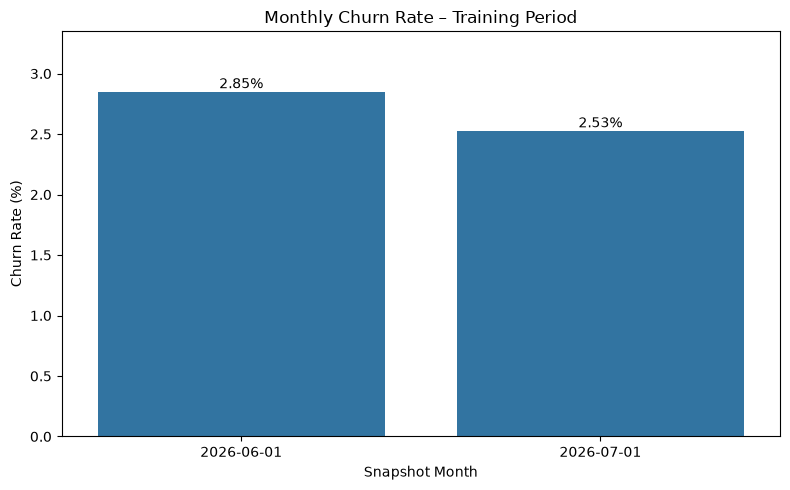

In [18]:
# Visualize

plt.figure(figsize=(8, 5))

sns.barplot(
    data=monthly_churn,
    x="snapshot_month",
    y="churn_rate_pct"
)

plt.title("Monthly Churn Rate – Training Period")
plt.xlabel("Snapshot Month")
plt.ylabel("Churn Rate (%)")

for i, row in monthly_churn.iterrows():
    plt.text(
        i,
        row["churn_rate_pct"] + 0.03,
        f'{row["churn_rate_pct"]:.2f}%',
        ha="center"
    )

plt.ylim(0, monthly_churn["churn_rate_pct"].max() + 0.5)
plt.tight_layout()
plt.show()

**Key findings:**

- The churn rate decreased slightly from 2.85% in June 2026 to 2.53% in July 2026, a decline of 0.32 percentage points.
- Despite the small decrease, the churn rate remained within a relatively narrow range of 2.5%–2.9% across the training period.
- This suggests that the target distribution was relatively stable between the two training months.
- However, only two months are available for training, so this observation is insufficient to establish long-term churn stability.

## C. Modelling

### 1. Define features, target and groups

In [19]:
TARGET = "churn_next_30d"

EXCLUDE_COLUMNS = [
    "shop_key",          # Used only for grouped cross-validation
    "snapshot_month",    # Excluded from baseline features
    "split",             # Dataset partition indicator
    TARGET
]

# Training data: June + July only
X_train = train_eda.drop(columns=EXCLUDE_COLUMNS)
y_train = train_eda[TARGET]
groups_train = train_eda["shop_key"]

# Inspect feature structure
print("Training feature shape:", X_train.shape)
print("Target shape:", y_train.shape)
print("\nFeature data types:")
print(X_train.dtypes.value_counts())

print("\nCategorical features:")
print(X_train.select_dtypes(include=["object", "category"]).columns.tolist())

print("\nNumeric features:")
print(X_train.select_dtypes(include=["number"]).columns.tolist())

print("\nTarget distribution:")
print(y_train.value_counts())

Training feature shape: (17181, 44)
Target shape: (17181,)

Feature data types:
float64     36
int64        4
str          2
category     1
category     1
Name: count, dtype: int64

Categorical features:
['mrr_movement_type', 'gmv_currency_code', 'tenure_group', 'mrr_group']

Numeric features:
['tenure_months', 'bom_mrr', 'eom_mrr', 'mrr_change', 'mrr_growth_rate', 'has_search_data', 'searches_30d', 'product_clicks_30d', 'search_clicks_30d', 'add_carts_30d', 'orders_30d', 'gmv_30d', 'gmv_60d', 'gmv_growth_30d', 'gmv_growth_60d', 'has_gmv_data', 'multi_currency_flag', 'searches_60d', 'product_clicks_60d', 'search_clicks_60d', 'add_carts_60d', 'orders_60d', 'searches_growth_30d', 'product_clicks_growth_30d', 'search_clicks_growth_30d', 'add_carts_growth_30d', 'orders_growth_30d', 'searches_growth_60d', 'product_clicks_growth_60d', 'search_clicks_growth_60d', 'add_carts_growth_60d', 'orders_growth_60d', 'search_to_product_click_rate_30d', 'search_click_rate_30d', 'product_click_to_cart_ra

C:\Users\HP\AppData\Local\Temp\ipykernel_9040\1705641688.py:22: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  print(X_train.select_dtypes(include=["object", "category"]).columns.tolist())


### 2. Remove EDA-only features from modeling

In [20]:
EDA_ONLY_COLUMNS = [
    "tenure_group",
    "mrr_group"
]

X_train = X_train.drop(columns=EDA_ONLY_COLUMNS)

# Identify feature groups
binary_features = [
    "has_search_data",
    "has_gmv_data",
    "multi_currency_flag"
]

categorical_features = [
    "mrr_movement_type",
    "gmv_currency_code"
]

numeric_features = [
    col for col in X_train.select_dtypes(include=["number"]).columns
    if col not in binary_features
]

print("Total features:", X_train.shape[1])
print("Numeric features:", len(numeric_features))
print("Binary features:", len(binary_features))
print("Categorical features:", len(categorical_features))

print("\nCategorical values:")
for feature in categorical_features:
    print(f"\n{feature}:")
    print(X_train[feature].value_counts(dropna=False))

Total features: 42
Numeric features: 37
Binary features: 3
Categorical features: 2

Categorical values:

mrr_movement_type:
mrr_movement_type
unchanged    16826
new_mrr        228
increased       97
decreased       30
Name: count, dtype: int64

gmv_currency_code:
gmv_currency_code
USD    5949
NaN    2453
GBP    1833
EUR    1739
AUD    1378
       ... 
RSD       2
NGN       2
GEL       2
BWP       1
KRW       1
Name: count, Length: 68, dtype: int64


### 3. Inspect missing values and binary features

In [21]:
# Missing values by feature group
missing_by_group = pd.DataFrame({
    "feature_group": (
        ["Numeric"] * len(numeric_features)
        + ["Binary"] * len(binary_features)
        + ["Categorical"] * len(categorical_features)
    ),
    "feature": numeric_features + binary_features + categorical_features,
    "missing_count": [
        X_train[col].isna().sum()
        for col in numeric_features + binary_features + categorical_features
    ]
})

display(
    missing_by_group[
        missing_by_group["missing_count"] > 0
    ].sort_values("missing_count", ascending=False)
)

# Check binary feature values
print("\nBinary feature distributions:")

for feature in binary_features:
    print(f"\n{feature}:")
    print(X_train[feature].value_counts(dropna=False))

,feature_group,feature,missing_count
23,Numeric,orders_growth_30d,9906
28,Numeric,orders_growth_60d,9321
22,Numeric,add_carts_growth_30d,7932
32,Numeric,cart_to_order_rate_30d,7862
27,Numeric,add_carts_growth_60d,7720
36,Numeric,cart_to_order_rate_60d,7504
25,Numeric,product_clicks_growth_60d,7045
26,Numeric,search_clicks_growth_60d,7045
21,Numeric,search_clicks_growth_30d,7029
20,Numeric,product_clicks_growth_30d,7029



Binary feature distributions:

has_search_data:
has_search_data
1    12700
0     4481
Name: count, dtype: int64

has_gmv_data:
has_gmv_data
1    14828
0     2353
Name: count, dtype: int64

multi_currency_flag:
multi_currency_flag
0    17081
1      100
Name: count, dtype: int64


### 4. Prepare preprocessing components

In [23]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer, MissingIndicator
from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder,
    FunctionTransformer
)
import numpy as np

# Numeric features to log-transform
log_features = [
    "bom_mrr",
    "eom_mrr",
    "gmv_30d",
    "gmv_60d",
    "searches_30d",
    "product_clicks_30d",
    "search_clicks_30d",
    "add_carts_30d",
    "orders_30d",
    "searches_60d",
    "product_clicks_60d",
    "search_clicks_60d",
    "add_carts_60d",
    "orders_60d"
]

# Other numeric features
other_numeric_features = [
    col for col in numeric_features
    if col not in log_features
]

print("Log-transformed features:", len(log_features))
print("Other numeric features:", len(other_numeric_features))
print("Binary features:", len(binary_features))
print("Categorical features:", len(categorical_features))
print("\nOther numeric features:")
print(other_numeric_features)

Log-transformed features: 14
Other numeric features: 23
Binary features: 3
Categorical features: 2

Other numeric features:
['tenure_months', 'mrr_change', 'mrr_growth_rate', 'gmv_growth_30d', 'gmv_growth_60d', 'searches_growth_30d', 'product_clicks_growth_30d', 'search_clicks_growth_30d', 'add_carts_growth_30d', 'orders_growth_30d', 'searches_growth_60d', 'product_clicks_growth_60d', 'search_clicks_growth_60d', 'add_carts_growth_60d', 'orders_growth_60d', 'search_to_product_click_rate_30d', 'search_click_rate_30d', 'product_click_to_cart_rate_30d', 'cart_to_order_rate_30d', 'search_to_product_click_rate_60d', 'search_click_rate_60d', 'product_click_to_cart_rate_60d', 'cart_to_order_rate_60d']


### 5. Build preprocessing transformer

In [24]:

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer, MissingIndicator
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.linear_model import LogisticRegression
import numpy as np

# Ensure categorical columns support the "Missing" category
X_train[categorical_features] = (
    X_train[categorical_features].astype("object")
)

# Pipeline for non-negative numeric features
log_numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("log_transform", FunctionTransformer(np.log1p)),
    ("scaler", StandardScaler())
])

# Pipeline for other numeric features
other_numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Pipeline for categorical features
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(
        strategy="constant",
        fill_value="Missing"
    )),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Combine all preprocessing branches
preprocessor = ColumnTransformer(
    transformers=[
        ("log_numeric", log_numeric_pipeline, log_features),
        ("other_numeric", other_numeric_pipeline, other_numeric_features),
        ("binary", "passthrough", binary_features),
        ("categorical", categorical_pipeline, categorical_features),
        ("missing_indicators", MissingIndicator(features="all"), numeric_features)
    ],
    remainder="drop"
)

print("Preprocessing transformer created successfully!")
print("Total input features:", X_train.shape[1])
print("Log numeric:", len(log_features))
print("Other numeric:", len(other_numeric_features))
print("Binary:", len(binary_features))
print("Categorical:", len(categorical_features))
print("Missing indicators:", len(numeric_features))

Preprocessing transformer created successfully!
Total input features: 42
Log numeric: 14
Other numeric: 23
Binary: 3
Categorical: 2
Missing indicators: 37


### 6. Grouped Cross-Validation

In [25]:
from sklearn.model_selection import StratifiedGroupKFold

# Match merchant IDs to the exact row order in X_train
groups = train_eda.loc[X_train.index, "shop_key"]

# Set up grouped stratified cross-validation
cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("Training samples:", len(X_train))
print("Unique merchants:", groups.nunique())
print("Number of CV folds:", cv.get_n_splits())
print("Churn rate:", round(y_train.mean() * 100, 2), "%")

Training samples: 17181
Unique merchants: 8768
Number of CV folds: 5
Churn rate: 2.69 %


### 7. Logistic Regression

#### 7.1. Logistic Regression baseline pipeline

In [27]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

logistic_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=2000,
        random_state=42
    ))
])

print("Logistic Regression pipeline created successfully!")
print("Class weight:", logistic_pipeline.named_steps["classifier"].class_weight)
print("Maximum iterations:", logistic_pipeline.named_steps["classifier"].max_iter)

Logistic Regression pipeline created successfully!
Class weight: balanced
Maximum iterations: 2000


#### 7.2. Cross-validation for Logistic Regression

In [28]:
from sklearn.base import clone
from sklearn.metrics import roc_auc_score, average_precision_score
import numpy as np
import pandas as pd

def calculate_top_k_metrics(y_true, y_score, k_percent):
    y_true = np.asarray(y_true)
    y_score = np.asarray(y_score)

    # Select the top K% merchants with the highest churn probability
    k = max(1, int(np.ceil(len(y_true) * k_percent)))
    top_indices = np.argsort(y_score)[-k:]

    precision = y_true[top_indices].mean()
    recall = y_true[top_indices].sum() / y_true.sum()
    lift = precision / y_true.mean()

    return precision, recall, lift


logistic_results = []

for fold, (tr_idx, val_idx) in enumerate(
    cv.split(X_train, y_train, groups=groups),
    start=1
):
    # Split data
    X_tr, X_val = X_train.iloc[tr_idx], X_train.iloc[val_idx]
    y_tr, y_val = y_train.iloc[tr_idx], y_train.iloc[val_idx]

    # Create a fresh pipeline for each fold
    model = clone(logistic_pipeline)

    # Train and predict
    model.fit(X_tr, y_tr)
    y_score = model.predict_proba(X_val)[:, 1]

    # Calculate ranking metrics
    roc_auc = roc_auc_score(y_val, y_score)
    pr_auc = average_precision_score(y_val, y_score)

    p5, r5, l5 = calculate_top_k_metrics(y_val, y_score, 0.05)
    p10, r10, l10 = calculate_top_k_metrics(y_val, y_score, 0.10)

    logistic_results.append({
        "fold": fold,
        "roc_auc": roc_auc,
        "pr_auc": pr_auc,
        "precision_at_5%": p5,
        "recall_at_5%": r5,
        "lift_at_5%": l5,
        "precision_at_10%": p10,
        "recall_at_10%": r10,
        "lift_at_10%": l10
    })

logistic_cv_results = pd.DataFrame(logistic_results)

display(logistic_cv_results.round(4))

print("\nMean CV performance:")
display(
    logistic_cv_results.drop(columns="fold")
    .agg(["mean", "std"])
    .round(4)
)

,fold,roc_auc,pr_auc,precision_at_5%,recall_at_5%,lift_at_5%,precision_at_10%,recall_at_10%,lift_at_10%
0,1,0.6776,0.1092,0.1047,0.1957,3.9085,0.0814,0.3043,3.0399
1,2,0.6466,0.0599,0.0756,0.1413,2.8228,0.0640,0.2391,2.3885
2,3,0.6772,0.0710,0.0930,0.1739,3.4742,0.0785,0.2935,2.9314
3,4,0.6605,0.0715,0.0698,0.1290,2.5784,0.0523,0.1935,1.9338
4,5,0.6862,0.1229,0.1221,0.2258,4.5109,0.0901,0.3333,3.3295



Mean CV performance:


,roc_auc,pr_auc,precision_at_5%,recall_at_5%,lift_at_5%,precision_at_10%,recall_at_10%,lift_at_10%
mean,0.6696,0.0869,0.0930,0.1731,3.4590,0.0733,0.2728,2.7246
std,0.0159,0.0274,0.0214,0.0395,0.7888,0.0150,0.0559,0.5582


### 8. Random Forest

#### 8.1. Build Random Forest baseline pipeline

In [30]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

random_forest_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        max_features="sqrt",
        min_samples_leaf=5,
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=-1
    ))
])

print("Random Forest baseline pipeline created successfully!")
print("Number of trees:", 300)
print("Class weight:", "balanced_subsample")
print("Minimum samples per leaf:", 5)

Random Forest baseline pipeline created successfully!
Number of trees: 300
Class weight: balanced_subsample
Minimum samples per leaf: 5


#### 8.2. Cross-validation for Random Forest

In [31]:
from sklearn.base import clone
from sklearn.metrics import roc_auc_score, average_precision_score
import numpy as np
import pandas as pd

rf_results = []

for fold, (tr_idx, val_idx) in enumerate(
    cv.split(X_train, y_train, groups=groups),
    start=1
):
    X_tr, X_val = X_train.iloc[tr_idx], X_train.iloc[val_idx]
    y_tr, y_val = y_train.iloc[tr_idx], y_train.iloc[val_idx]

    model = clone(random_forest_pipeline)

    model.fit(X_tr, y_tr)
    y_score = model.predict_proba(X_val)[:, 1]

    roc_auc = roc_auc_score(y_val, y_score)
    pr_auc = average_precision_score(y_val, y_score)

    p5, r5, l5 = calculate_top_k_metrics(y_val, y_score, 0.05)
    p10, r10, l10 = calculate_top_k_metrics(y_val, y_score, 0.10)

    rf_results.append({
        "fold": fold,
        "roc_auc": roc_auc,
        "pr_auc": pr_auc,
        "precision_at_5%": p5,
        "recall_at_5%": r5,
        "lift_at_5%": l5,
        "precision_at_10%": p10,
        "recall_at_10%": r10,
        "lift_at_10%": l10
    })

rf_cv_results = pd.DataFrame(rf_results)

print("Random Forest - Fold results:")
display(rf_cv_results.round(4))

print("\nRandom Forest - Mean CV performance:")
display(
    rf_cv_results.drop(columns="fold")
    .agg(["mean", "std"])
    .round(4)
)

Random Forest - Fold results:


,fold,roc_auc,pr_auc,precision_at_5%,recall_at_5%,lift_at_5%,precision_at_10%,recall_at_10%,lift_at_10%
0,1,0.7075,0.0984,0.0988,0.1848,3.6914,0.0843,0.3152,3.1485
1,2,0.6682,0.0809,0.1047,0.1957,3.9085,0.0698,0.2609,2.6057
2,3,0.7242,0.0668,0.0523,0.0978,1.9542,0.0610,0.2283,2.2800
3,4,0.6877,0.0582,0.0640,0.1183,2.3635,0.0640,0.2366,2.3635
4,5,0.7028,0.0683,0.0756,0.1398,2.7924,0.0669,0.2473,2.4702



Random Forest - Mean CV performance:


,roc_auc,pr_auc,precision_at_5%,recall_at_5%,lift_at_5%,precision_at_10%,recall_at_10%,lift_at_10%
mean,0.6981,0.0745,0.0791,0.1473,2.9420,0.0692,0.2576,2.5736
std,0.0212,0.0156,0.0224,0.0421,0.8409,0.0091,0.0344,0.3437


### 9. HistGradientBoostingClassifier

In [33]:
import sklearn

print("Scikit-learn version:", sklearn.__version__)

Scikit-learn version: 1.9.1


### 10. Model comparison

In [32]:
model_comparison = pd.DataFrame([
    {
        "model": "Logistic Regression",
        "roc_auc_mean": logistic_cv_results["roc_auc"].mean(),
        "pr_auc_mean": logistic_cv_results["pr_auc"].mean(),
        "lift_at_5%": logistic_cv_results["lift_at_5%"].mean(),
        "lift_at_10%": logistic_cv_results["lift_at_10%"].mean()
    },
    {
        "model": "Random Forest",
        "roc_auc_mean": rf_cv_results["roc_auc"].mean(),
        "pr_auc_mean": rf_cv_results["pr_auc"].mean(),
        "lift_at_5%": rf_cv_results["lift_at_5%"].mean(),
        "lift_at_10%": rf_cv_results["lift_at_10%"].mean()
    }
])

display(model_comparison.round(4))

,model,roc_auc_mean,pr_auc_mean,lift_at_5%,lift_at_10%
0,Logistic Regression,0.6696,0.0869,3.459,2.7246
1,Random Forest,0.6981,0.0745,2.942,2.5736
